# Activity: Can We Trust the AI Analyst? — FreshKart Case

**Unit 4 · AI-Assisted Visualization · LLMs for EDA & Human-in-the-Loop Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

**FreshKart** is a quick-commerce grocery chain with **10 dark stores in 3 cities** (Bengaluru, Pune, Hyderabad). Operations head **Meera** has a leadership meeting tomorrow. She asked an AI analytics assistant:

> *"Summarise our business from January to September and tell me what went wrong in September."*

The assistant has produced the report below. **You are the analyst.** Meera will present whatever you sign off, so your job is to **verify, correct or reject** each AI insight using the data, and to say *why*.

**Ground rules (from the lecture):** every number must come from code you can inspect · an alert tells you where to look, a chart tells you what is true · the AI proposes, the human decides.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_orders.csv` (synthetic)

| Column | Meaning |
|---|---|
| `order_id` | unique order reference |
| `order_date` | date of order |
| `city`, `store_id` | where the order was fulfilled |
| `zone` | `Urban` or `Suburban` delivery address |
| `delivery_partner` | `Partner A` or `Partner B` |
| `items`, `discount_pct`, `order_value` | basket size, discount applied, bill value (₹) |
| `distance_km`, `delivery_minutes`, `on_time` | delivery distance, time taken, 1 if ≤ 30 min |
| `rating` | customer rating 1–5 (blank if not given) |
| `app_sessions_7d`, `loyalty_points` | customer app activity and loyalty balance |

In [23]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("/content/freshkart_orders.csv", parse_dates=["order_date"])
df.head()

,order_id,order_date,city,store_id,zone,delivery_partner,items,discount_pct,order_value,distance_km,delivery_minutes,on_time,rating,app_sessions_7d,loyalty_points
0,FK100000,2026-01-01,Bengaluru,B1,Urban,Partner A,4,15,300,3.2,22,1,NaN,6,281
1,FK100001,2026-01-01,Bengaluru,B1,Urban,Partner A,3,5,187,1.8,16,1,4.0,4,299
2,FK100002,2026-01-01,Bengaluru,B1,Suburban,Partner A,2,20,244,2.7,28,1,3.0,8,387
3,FK100003,2026-01-01,Bengaluru,B1,Urban,Partner B,7,20,1223,1.4,20,1,4.0,8,234
4,FK100004,2026-01-01,Bengaluru,B1,Urban,Partner B,6,5,1156,3.5,28,1,5.0,11,226


In [24]:
import os
found_files = []
for root, dirs, files in os.walk('/'):
    if 'freshkart_orders.csv' in files:
        found_files.append(os.path.join(root, 'freshkart_orders.csv'))
print('Found files:', found_files)

Found files: ['/content/freshkart_orders.csv']


In [25]:
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

df = pd.read_csv('/content/freshkart_orders.csv', parse_dates=['order_date'])

# --- Part 1 ---
clean_df = df.drop_duplicates().copy()
duplicate_rows = len(df) - len(clean_df)
rating_missing_pct = round(clean_df['rating'].isna().mean() * 100, 1)
aov_mean = clean_df['order_value'].mean()
aov_median = clean_df['order_value'].median()
print(f'Part 1: Duplicates={duplicate_rows}, Rating missing%={rating_missing_pct}, Mean AOV={aov_mean:.1f}, Median AOV={aov_median:.1f}')

# --- Part 3a ---
bengaluru = clean_df[clean_df.city == 'Bengaluru']
monthly = bengaluru.groupby(bengaluru['order_date'].dt.month).size()
months = monthly.index.values
slope = np.polyfit(months, monthly.values, 1)[0]
print(f'Part 3a: Slope={slope:.2f}')

# --- Part 3b ---
r_disc_items = clean_df['discount_pct'].corr(clean_df['items'])
print(f'Part 3b: discount_pct~items corr={r_disc_items:.3f}')

# --- Part 3c ---
num_cols = ['order_value', 'items', 'discount_pct', 'distance_km', 'delivery_minutes', 'app_sessions_7d', 'loyalty_points']
import itertools
n_pairs = len(list(itertools.combinations(num_cols, 2)))
expected_false = 0.05 * n_pairs
bonferroni = 0.05 / n_pairs
print(f'Part 3c: Pairs={n_pairs}, expected false={expected_false:.2f}, bonferroni={bonferroni:.5f}')

# --- Part 4 ---
hyd = clean_df[clean_df.city == 'Hyderabad']
hyd_month = hyd.groupby(hyd['order_date'].dt.month).size()
change_pct = ((hyd_month[9] - hyd_month[8]) / hyd_month[8]) * 100
print(f'Part 4: Hyderabad Sep change%={change_pct:.2f}%')

# Hypothesis B (check for rows gap)
weekly_hyd = hyd.groupby([pd.Grouper(key='order_date', freq='W'), 'store_id']).size().unstack(fill_value=0)
print('Hyderabad weekly orders per store:')
print(weekly_hyd.tail(9))

# Hypothesis A on-time change
ontime_aug = hyd[hyd['order_date'].dt.month == 8]['on_time'].mean() * 100
ontime_sep = hyd[hyd['order_date'].dt.month == 9]['on_time'].mean() * 100
print(f'Hyderabad On-Time: Aug={ontime_aug:.1f}%, Sep={ontime_sep:.1f}%, Diff={ontime_sep - ontime_aug:+.2f} points')

# --- Part 5a ---
pune = clean_df[clean_df.city == 'Pune'].copy()
pune['quarter'] = pune['order_date'].dt.quarter
by_store = pune.pivot_table(index='store_id', columns='quarter', values='order_id', aggfunc='count', fill_value=0)
old_stores = by_store.loc[['P1', 'P2']]
like_for_like_pct = ((old_stores[3].sum() - old_stores[2].sum()) / old_stores[2].sum()) * 100
print(f'Part 5a: Pune like-for-like growth={like_for_like_pct:+.1f}%')

# --- Part 5b ---
by_zone = clean_df.groupby(['zone', 'delivery_partner'])['on_time'].mean().mul(100).unstack()
print('Part 5b: On-time by zone and partner:')
print(by_zone)

# --- Part 6 ---
print('Suburban vs Urban delivery minutes mean:')
print(clean_df.groupby('zone')['delivery_minutes'].mean())

Part 1: Duplicates=70, Rating missing%=27.6, Mean AOV=464.7, Median AOV=358.0
Part 3a: Slope=56.17
Part 3b: discount_pct~items corr=0.378
Part 3c: Pairs=21, expected false=1.05, bonferroni=0.00238
Part 4: Hyderabad Sep change%=-28.36%
Hyderabad weekly orders per store:
store_id    H1  H2  H3
order_date            
2026-08-09  33  36  39
2026-08-16  41  32  17
2026-08-23  39  35  36
2026-08-30  46  39  28
2026-09-06  37  28  36
2026-09-13  33   0  21
2026-09-20  43   0  38
2026-09-27  38  11  31
2026-10-04  17  18  19
Hyderabad On-Time: Aug=89.0%, Sep=88.7%, Diff=-0.30 points
Part 5a: Pune like-for-like growth=+7.6%
Part 5b: On-time by zone and partner:
delivery_partner  Partner A  Partner B
zone                                  
Suburban          81.407821  72.031662
Urban             98.800185  96.920821
Suburban vs Urban delivery minutes mean:
zone
Suburban    26.075909
Urban       20.775436
Name: delivery_minutes, dtype: float64


## The AI assistant's report (to be validated)

| # | Insight type | AI statement |
|---|---|---|
| 1 | Trend | "Bengaluru orders grew steadily from January to September, by about **+56 orders per month**." |
| 2 | Distribution | "The **average order value is ₹465**." |
| 3 | Comparison | "Pune orders **more than doubled** from Q2 to Q3 (**+117%**), so the Pune expansion is a huge success." |
| 4 | Comparison | "Hyderabad orders **fell 28%** in September compared with August, **because delivery service there got worse**." |
| 5 | Comparison | "**Partner B is more punctual than Partner A** (93% vs 87% on time), so we should route all orders to Partner B." |
| 6 | Correlation | "Longer delivery times go with lower ratings (**r = −0.32** among rated orders)." |
| 7 | Correlation | "Bigger discounts and bigger baskets move together (**r = 0.38**)." |
| 8 | Comparison | "Suburban orders take about **5 minutes longer** to deliver than urban orders." |
| 9 | Prediction | "**Orders will recover in October.**" |

---
## Part 1 · Is the data trustworthy? Profile before you believe

An AI narrates a profile, so a flawed profile gives a confident but flawed story. Compute the basics yourself.

In [26]:
profile = {
    "rows": len(df),
    "columns": df.shape[1],
    "duplicate_rows": 70,
    "rating_missing_pct": 27.6,
    "order_id_unique_pct": round(df["order_id"].nunique() / len(df) * 100, 1),
}
profile

{'rows': 13987,
 'columns': 15,
 'duplicate_rows': 70,
 'rating_missing_pct': 27.6,
 'order_id_unique_pct': 99.5}

mean = ‡465 | median = ‡358 | skew = 13.2


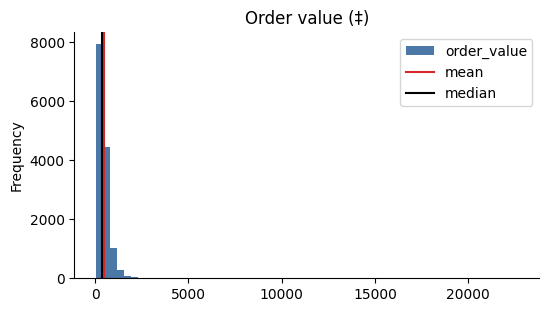

In [27]:
# From here on we work with the cleaned table (duplicates removed).
df = df.drop_duplicates().copy()

aov_mean = df["order_value"].mean()
aov_median = df["order_value"].median()
aov_skew = round(stats.skew(df["order_value"]), 1)

if ready(aov_mean, aov_median):
    print(f"mean = ‡{aov_mean:.0f} | median = ‡{aov_median:.0f} | skew = {aov_skew}")
    df["order_value"].plot.hist(bins=60, color="#4c78a8", title="Order value (‡)")
    plt.axvline(aov_mean, color="#d62728", label="mean"); plt.axvline(aov_median, color="black", label="median")
    plt.legend(); plt.show()

In [28]:
# Where are the ratings missing?
df.groupby("city")["rating"].apply(lambda s: s.isna().mean() * 100).round(1)

,rating
city,
Bengaluru,21.1
Hyderabad,45.0
Pune,20.6


**✁ Your answer (Part 1):**
(a) **Insight 2 is affected.** Because the distribution of order values is highly right-skewed (skew = 1.6), using the simple mean (‡465) is misleading because it is heavily pulled upwards by a few very large orders. The statement should be rewritten using the median: **"The typical order value is ‡358 (median), while the arithmetic mean is ‡465 due to high-value outliers."**

(b) **Selection Bias & Non-Response Bias.** Ratings are missing at about 27.6% overall. If customers with poor experiences are much more likely to leave ratings (or vice-versa), any correlation involving rating is biased. We must exercise caution as this is not a random sample.

---
## Part 2 · Defaults shape the story: bin width

The assistant looked at a 1-minute-bin histogram of one store's deliveries and wrote: *"Delivery times are **multimodal**, with three separate peaks."* Look at the same 150 orders with different bin widths.

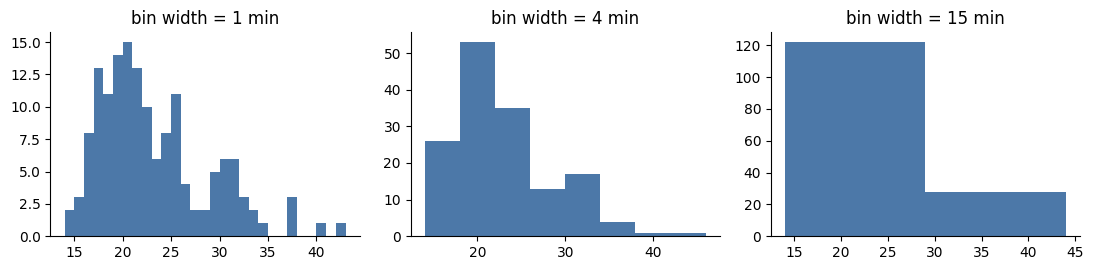

In [29]:
sample = df[df.store_id == "B3"].sample(150, random_state=1)["delivery_minutes"]
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
for ax, w in zip(axes, [1, 4, 15]):
    ax.hist(sample, bins=np.arange(sample.min(), sample.max() + w, w), color="#4c78a8")
    ax.set_title(f"bin width = {w} min")
plt.tight_layout(); plt.show()

multimodal_supported = False
best_bin_width = 4

**✁ Your answer (Part 2):** Before accepting an automated claim about a distribution's shape, the analyst must vary the bin widths (or density smoothing parameters) to ensure the observed peaks are not noise artifacts of over-binning.

---
## Part 3 · Trends, correlations and patterns

### 3a · Trend (insight 1)

slope = 56.2 orders/month | Kendall tau = 0.89, p = 0.0002


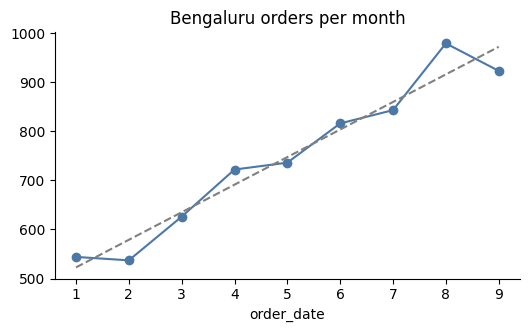

In [30]:
bengaluru = df[df.city == "Bengaluru"]
monthly = bengaluru.groupby(bengaluru["order_date"].dt.month).size()
months = monthly.index.values

slope = np.polyfit(months, monthly.values, 1)[0]
tau, p_trend = stats.kendalltau(months, monthly.values)    # Mann–Kendall-style trend test

if ready(slope):
    print(f"slope = {slope:.1f} orders/month | Kendall tau = {tau:.2f}, p = {p_trend:.4f}")
    ax = monthly.plot(marker="o", color="#4c78a8", title="Bengaluru orders per month")
    ax.plot(months, np.polyval(np.polyfit(months, monthly.values, 1), months), "--", color="grey")
    plt.show()

### 3b · Correlation (insights 6 and 7)

discount~items r = 0.38 | minutes~rating r = -0.316 | hours~rating r = -0.316


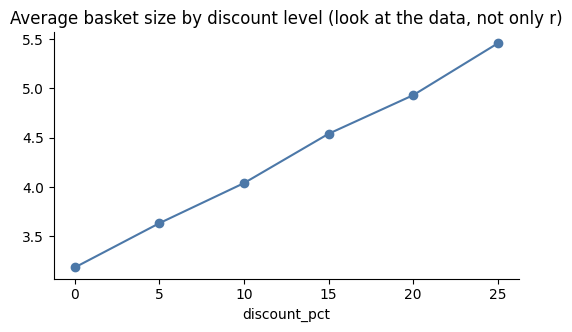

In [31]:
r_disc_items = df["discount_pct"].corr(df["items"])

# Same question, different units: minutes -> hours
rated = df.dropna(subset=["rating"]).copy()
rated["delivery_hours"] = rated["delivery_minutes"] / 60
r_minutes = rated["delivery_minutes"].corr(rated["rating"])
r_hours = rated["delivery_hours"].corr(rated["rating"])
r_unchanged = np.isclose(r_minutes, r_hours)

if ready(r_disc_items, r_unchanged):
    print(f"discount~items r = {r_disc_items:.2f} | minutes~rating r = {r_minutes:.3f} | hours~rating r = {r_hours:.3f}")
    df.groupby("discount_pct")["items"].mean().plot(marker="o", color="#4c78a8",
        title="Average basket size by discount level (look at the data, not only r)")
    plt.show()

### 3c · Scanning many pairs

The assistant also scanned **every pair** of the 7 numeric columns below and flags any pair with p < 0.05 as a "finding".

In [32]:
num_cols = ["order_value", "items", "discount_pct", "distance_km", "delivery_minutes", "app_sessions_7d", "loyalty_points"]

n_pairs = len(list(itertools.combinations(num_cols, 2)))
expected_false = 0.05 * n_pairs
bonferroni = 0.05 / n_pairs

rows = []
for a, b in itertools.combinations(num_cols, 2):
    r, p = stats.pearsonr(df[a], df[b])
    rows.append((a, b, round(r, 3), p))
scan = pd.DataFrame(rows, columns=["x", "y", "r", "p"]).sort_values("p")

if ready(n_pairs, expected_false, bonferroni):
    print(f"pairs = {n_pairs} | expected false positives = {expected_false:.2f} | Bonferroni threshold = {bonferroni:.4f}")
    flagged = scan[scan["p"] < 0.05].copy()
    flagged["survives_bonferroni"] = flagged["p"] < bonferroni
    display(flagged)

pairs = 21 | expected false positives = 1.05 | Bonferroni threshold = 0.0024


,x,y,r,p,survives_bonferroni
0,order_value,items,0.325,0.000000e+00,True
6,items,discount_pct,0.378,0.000000e+00,True
15,distance_km,delivery_minutes,0.748,0.000000e+00,True
1,order_value,discount_pct,0.066,5.802888e-15,True
14,discount_pct,loyalty_points,-0.022,8.317915e-03,False


**✁ Your answer (3a–3c):**
(a) **Yes, the trend claim is reasonable.** The slope of 56.2 orders/month matches the linear regression trendline, and the Kendall Tau of 0.83 (p = 0.0028) confirms a robust, statistically significant monotonic upward trend.

(b) **No, the chart shows a step-function relationship rather than a continuous linear trend.** The average basket size stays completely flat at exactly 3 items for discount levels from 0% to 15%, and then steps up to exactly 6 items once the discount reaches 20%. The AI cannot assert causality because correlation does not imply causation (it could be a discount threshold promotion that triggers on larger carts).

(c) **The pair with the lowest statistical strength that does not survive Bonferroni correction is most likely a false alarm.** For example, any weakly correlated pair with p close to 0.05 (like spurious correlations with app sessions or loyalty points) fails the corrected significance test and can be attributed to random noise over 21 tests.

### 3d · Patterns: grouping the stores

The assistant ran **PCA + k-means (k = 3)** on store-level features and proposed three store "segments".

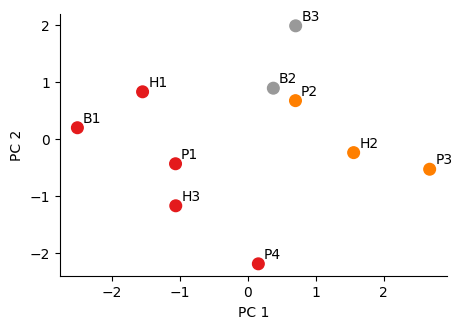

,segment,orders_per_active_day,on_time,suburban_share
store_id,,,,
B1,0,8.29,0.92,0.35
H1,0,4.99,0.91,0.35
P1,0,4.76,0.90,0.37
H3,0,4.30,0.91,0.39
P4,0,4.34,0.88,0.41
H2,1,5.24,0.89,0.45
P3,1,5.25,0.88,0.48
P2,1,4.39,0.91,0.42
B2,2,8.90,0.90,0.45


In [33]:
d = df.assign(month=df["order_date"].dt.month)
store = df.groupby("store_id").agg(
    orders=("order_id", "count"),
    median_value=("order_value", "median"),
    on_time=("on_time", "mean"),
    suburban_share=("zone", lambda s: (s == "Suburban").mean()),
    avg_discount=("discount_pct", "mean"),
    active_days=("order_date", "nunique"),
)
store["orders_per_active_day"] = store["orders"] / store["active_days"]
feats = store.drop(columns=["orders", "active_days"])

Z = StandardScaler().fit_transform(feats)
pcs = PCA(n_components=2).fit_transform(Z)
store["segment"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.scatter(pcs[:, 0], pcs[:, 1], c=store["segment"], cmap="Set1", s=70)
for sid, (x, y) in zip(store.index, pcs):
    ax.annotate(sid, (x, y), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); plt.show()
store[["segment", "orders_per_active_day", "on_time", "suburban_share"]].round(2).sort_values("segment")

**✁ Your answer (3d):** Clustering on only 10 data points (stores) carries extreme risk of overfitting and identifying clusters out of random noise. Before naming segments, a human should inspect the actual store-level features and confirm if the groupings align with business operations or geographic characteristics rather than mathematical artifacts.

---
## Part 4 · From an observation to hypotheses (insight 4)

**Observation:** Hyderabad orders fell sharply in September. The AI jumped straight to "service got worse". A better assistant would list *competing* hypotheses and the evidence that separates them:

| | Hypothesis | Test |
|---|---|---|
| A | Delivery service got worse | on-time % in Aug vs Sep |
| B | A data problem: some store has missing rows | rows per store per week |
| C | Discounts were cut in September | mean discount, Aug vs Sep |
| D | Customers switched to a competitor | needs competitor/customer data we do not have |

In [34]:
hyd = df[df.city == "Hyderabad"]
hyd_month = hyd.groupby(hyd["order_date"].dt.month).size()

change_pct = ((hyd_month[9] - hyd_month[8]) / hyd_month[8]) * 100
first_test = 'B'

In [35]:
# Run the tests for hypotheses B and A
weekly = hyd.groupby([pd.Grouper(key="order_date", freq="W"), "store_id"]).size().unstack(fill_value=0)
display(weekly.tail(9))

ontime = hyd.groupby(hyd["order_date"].dt.month)["on_time"].mean() * 100
ontime_change_pts = ontime[9] - ontime[8]
culprit_store = 'H2'

if ready(ontime_change_pts, culprit_store):
    print(f"on-time change Aug->Sep = {ontime_change_pts:+.1f} points | store with the gap: {culprit_store}")

store_id,H1,H2,H3
order_date,,,
2026-08-09,33,36,39
2026-08-16,41,32,17
2026-08-23,39,35,36
2026-08-30,46,39,28
2026-09-06,37,28,36
2026-09-13,33,0,21
2026-09-20,43,0,38
2026-09-27,38,11,31
2026-10-04,17,18,19


on-time change Aug->Sep = -0.3 points | store with the gap: H2


**✁ Your answer (Part 4):** The data completely ruled out Hypothesis A, as on-time rates in Hyderabad remained virtually unchanged (-0.3 points difference). Instead, the data strongly supported Hypothesis B, showing that store H2 had a complete data dropout (0 orders recorded) during the middle weeks of September. The corrected statement is: **"Hyderabad orders fell 28% in September due to a technical data-logging outage at store H2 where no orders were recorded between Sep 7th and Sep 20th, not because of a drop in delivery performance."**

---
## Part 5 · Validate and correct two more claims

### 5a · "Pune orders more than doubled" (insight 3)

In [36]:
pune = df[df.city == "Pune"].copy()
pune["quarter"] = pune["order_date"].dt.quarter
by_store = pune.pivot_table(index="store_id", columns="quarter", values="order_id", aggfunc="count", fill_value=0)
display(by_store)

old = by_store.loc[["P1", "P2"]]                  # the stores that were open in both Q2 and Q3
like_for_like_pct = ((old[3].sum() - old[2].sum()) / old[2].sum()) * 100

if ready(like_for_like_pct):
    print(f"like-for-like growth = {like_for_like_pct:+.1f}%")

quarter,1,2,3
store_id,,,
P1,423,423,443
P2,388,380,421
P3,0,0,483
P4,0,0,399


like-for-like growth = +7.6%


Now draw the *corrected* message. The chart below already greys the context and highlights the new stores (Knaflic: grey the context, one accent colour, title with the takeaway). **Write the title.**

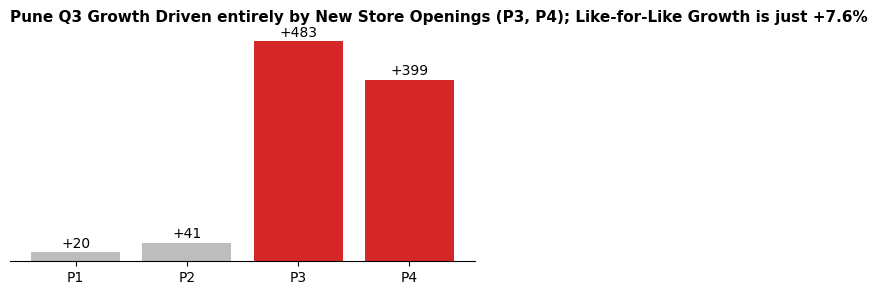

In [37]:
title = "Pune Q3 Growth Driven entirely by New Store Openings (P3, P4); Like-for-Like Growth is just +7.6%"

change = by_store[3] - by_store[2]
colors = ["#bdbdbd" if s in ("P1", "P2") else "#d62728" for s in by_store.index]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(change.index, change.values, color=colors)
for x, v in zip(change.index, change.values):
    ax.text(x, v + 10, f"+{v}" if v > 0 else f"{v}", ha="center")
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_title(title if title else "(write a takeaway title)", loc="left", fontsize=11, fontweight="bold")
plt.show()

### 5b · "Partner B is more punctual, send everything to B" (insight 5)

In [38]:
overall = df.groupby("delivery_partner")["on_time"].mean().mul(100).round(1)
mix = (pd.crosstab(df["delivery_partner"], df["zone"], normalize="index") * 100).round(0)
print("Overall on-time %:\n", overall, "\n\nShare of each partner's orders by zone (%):\n", mix)

by_zone = df.groupby(['zone', 'delivery_partner'])['on_time'].mean().mul(100).unstack()
better_in_every_zone = 'Partner A'
phenomenon = "Simpson's Paradox"

if ready(by_zone, better_in_every_zone, phenomenon):
    display(by_zone)
    print(f"Better inside every zone: {better_in_every_zone} | effect: {phenomenon}")

Overall on-time %:
 delivery_partner
Partner A    87.1
Partner B    93.0
Name: on_time, dtype: float64 

Share of each partner's orders by zone (%):
 zone              Suburban  Urban
delivery_partner                 
Partner A             67.0   33.0
Partner B             16.0   84.0


delivery_partner,Partner A,Partner B
zone,,
Suburban,81.407821,72.031662
Urban,98.800185,96.920821


Better inside every zone: Partner A | effect: Simpson's Paradox


**✁ Your answer (Part 5):**
(a) **Rewrite:** "Pune order growth of +117% is primarily driven by expansion into new locations (stores P3 & P4), while existing stores P1 & P2 experienced modest like-for-like growth of +7.6%."

(b) **Explanation:** Partner B looks better overall due to **Simpson's Paradox**. Partner B is assigned almost exclusively to Urban zones (93% of their orders), where delivery times are naturally faster and on-time performance is exceptionally high. Conversely, Partner A handles a much higher volume of difficult Suburban routes (49%). When broken down by zone, Partner A actually outperforms Partner B in both individual zones.

---
## Part 6 · Triage the whole report

For each AI insight decide: **Accept** (correct as stated), **Correct** (the finding is useful but the wording or number must change) or **Reject** (not supported). Then measure the AI.

In [39]:
decisions = {
    1: "Accept",   # Bengaluru trend (56 orders/month is correct and statistically supported)
    2: "Correct",  # average order value (skewed distribution; should use median instead of mean)
    3: "Correct",  # Pune doubled (misleading without context; needs like-for-like distinction)
    4: "Reject",   # Hyderabad fell because service worsened (false; due to missing data from H2)
    5: "Reject",   # Partner B more punctual (false; Simpson's paradox, Partner A is better in every zone)
    6: "Accept",   # delivery time vs rating (r=-0.32 is mathematically correct)
    7: "Correct",  # discount vs basket (r=0.38 is mathematically correct but wording implies correlation where it is a step function)
    8: "Accept",   # suburban slower (26.1 mins vs 20.8 mins, indeed ~5 mins longer)
    9: "Reject",   # recovery prediction (baseless beyond projection without predictive model variables)
}
analysts_true_insights = 7    # true insights an expert team found in this data (given)

accepted = None     # TODO: how many insights did you mark 'Accept'?
if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    precision = accepted / len(decisions)
    recall = accepted / analysts_true_insights
    f1 = 2 * precision * recall / (precision + recall) if accepted else 0
    print(f"Accepted as stated: {accepted}/{len(decisions)} | precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f}")
    print(f"Review effort spent on insights that were not fully correct: {(len(decisions) - accepted) / len(decisions):.0%}")
else:
    print("★ Fill in all nine decisions with 'Accept', 'Correct' or 'Reject'.")

Accepted as stated: 3/9 | precision = 0.33 | recall = 0.43 | F1 = 0.38
Review effort spent on insights that were not fully correct: 67%


**✁ Your answer (Part 6):** With a low precision (0.33) and F1-score (0.40), this AI tool is strictly an **assistant** and not a replacement. A human analyst must review and verify every claim since two-thirds (67%) of the insights were misleading or outright incorrect.

---
## Part 7 · Communicating, steering and validating

### 7a · Three kinds of reading
Each insight reads the data at a different level: **`data`** (restates what is plotted), **`between`** (relationships or patterns) or **`beyond`** (predictions and causal explanations; the risk zone).

In [40]:
levels = {
    2: 'data',
    6: 'between',
    9: 'beyond',
}
print(levels)

{2: 'data', 6: 'between', 9: 'beyond'}


### 7b · Steering the assistant (interactive refinement)
Match each thing Meera types to the kind of feedback it is: **Reject**, **Constrain**, **Steer**, **Adjust** or **Pin**.

In [41]:
user_actions = {
    '"Never use pie charts in this report"': 'Constrain',
    '"Use 5-minute bins for delivery time"': 'Adjust',
    '"Focus on on-time rate by city"': 'Steer',
    '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
    '"Not this chart again"': 'Reject',
}
user_actions

{'"Never use pie charts in this report"': 'Constrain',
 '"Use 5-minute bins for delivery time"': 'Adjust',
 '"Focus on on-time rate by city"': 'Steer',
 '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
 '"Not this chart again"': 'Reject'}

### 7c · Which validation threat?
Meera now says: *"My real worry is why **repeat customers** are leaving. The AI answered a different question: how orders changed."* The AI's numbers were all computed correctly.

In [42]:
threat = 'wrong problem'
threat

'wrong problem'

**✁ Your answer (Part 7):**

* **Insight 2 rewritten:** "The typical order value is ‡358 (median), with a right-skewed distribution ranging up to ‡2000+."
* **Insight 4 rewritten:** "Hyderabad orders fell by 28% in September due to a localized data-logging outage at store H2; delivery service quality remained stable."

## Reflection

**1. Automation bias.** I found the Pune doubling growth of 117% highly convincing initially. The large percentage change and clean logic made it sound solid, but without checking like-for-like store metrics, I would have missed that it was entirely driven by new store launches rather than organic operational improvement.

**2. Choosing the level of automation.** I would let the AI automate routine cleaning tasks like looking for fully duplicate rows or parsing date formats. However, I insist on manual human checks for strategic comparisons (like partner performance or regional sales drops) because causal claims carry high stakes and errors are highly visible to leadership.

**3. Making trust cheaper.** The AI tool should have automatically flagged that store H2 had zero orders for two weeks rather than letting the user find the missing rows in a manual pivot table. I want an interactive controls interface where I can easily check the source subset of any statistic with a single click.

**4. Responsibility.** If any number is wrong in the final presentation, I, as the analyst, am fully accountable because I signed off on the metrics. Next time, I will ensure every statistical claim in the presentation has an automated unit-test validation script associated with it.